In [1]:
import os, yaml, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter


In [2]:
base_data_path = "/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251113/"
start_date = "2023-03-15"
end_date = "2024-04-29"

date_range = pd.date_range(start=start_date, end=end_date, freq='d')
data_files = date_range.strftime(f"{base_data_path}veraset_%Y-%m-%d_PST_chunked.parquet")
files = []
for i, f in enumerate(data_files):
    if os.path.isfile(f):
        if any(s in f for s in ["2024-03-29", "2024-03-30", "2024-03-31", "2024-04-01"]):
            continue
        files.append(f)
print(len(files))

88


In [3]:
dates = []
rows = []
for file in files:
    df_temp = pd.read_parquet(file)
    rows.append([(df_temp["number_of_visits"] > threshold).sum() for threshold in np.arange(0,100,10)])
    dates.append(df_temp["date"].iloc[0])
df_ping_counts = pd.DataFrame(rows, columns=np.arange(1,101,10), index=pd.DatetimeIndex(data=dates))
df_ping_counts

,1,11,21,31,41,51,61,71,81,91
2023-03-15,821536,492075,367803,289824,234612,193240,162113,138192,118821,102930
2023-03-16,783966,460199,344548,272723,222109,184078,155621,133611,116005,101691
2023-03-17,806325,476234,355794,279513,225052,184596,154426,131389,113337,98644
2023-03-18,813693,472357,345882,266920,212433,173452,144874,123504,106615,92970
2023-03-19,843609,505194,375733,292988,235093,192041,160359,136132,117005,101347
...,...,...,...,...,...,...,...,...,...,...
2024-04-25,1828726,616756,343362,224142,160111,119767,92500,73602,59335,48723
2024-04-26,1900417,691867,399489,269102,197551,152677,122098,99645,82213,68684
2024-04-27,1782287,573472,329217,215352,153581,115306,88847,70293,56644,46390
2024-04-28,1796742,595351,344961,231684,168876,128393,100713,80078,64458,52088


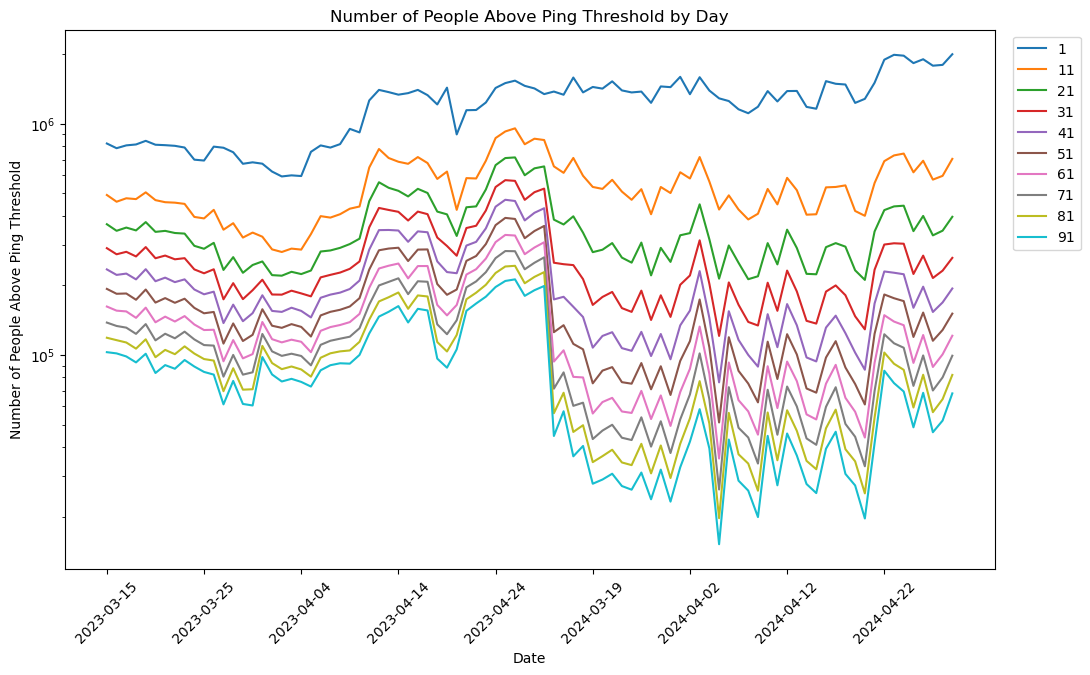

In [5]:
ax = df_ping_counts.reset_index(drop=True).plot(kind="line",
                                       figsize=(12, 7),
                                       logy=True,
                                       title="Number of People Above Ping Threshold by Day")
ax.set_xticks(df_ping_counts.reset_index(drop=True).index[0:100:10],
              df_ping_counts.index.date[0:100:10],
              rotation=45)
ax.set_xlabel('Date')
ax.set_ylabel('Number of People Above Ping Threshold')
ax.legend(title='Series')
ax.legend(bbox_to_anchor=(1.1, 1), loc='upper right')
plt.show()

In [6]:
min_pings_list = [0,9,19,29,59,99]
uids_dict = {k+1: [] for k in min_pings_list}
for file in files:
    for min_pings in min_pings_list:
        df_temp = pd.read_parquet(file)
        uids_dict[min_pings+1] += df_temp[df_temp["number_of_visits"] > min_pings].uid.unique().tolist()

In [7]:
home_loc_file = "home_loc_by_row_group_counties_unfiltered.parquet"
df_home_loc = pd.read_parquet(home_loc_file)

In [8]:
min_pings_list = [0,9,19,29,59,99]
count_dict = {k+1: {} for k in min_pings_list}
thresholds = np.arange(0,88)

for min_pings in min_pings_list:
    count_dict[min_pings+1] = {t+1: {} for t in thresholds}
    counter = Counter(uids_dict[min_pings+1])
    for threshold in thresholds:
        uids = [key for key, value in counter.items() if value > threshold]
        count_dict[min_pings+1][threshold+1]["LASBVE"] = len(uids)
        counter_county = Counter(df_home_loc["county"][df_home_loc.index.isin(uids)])
        for county in counter_county.keys():
            count_dict[min_pings+1][threshold+1][county] = counter_county[county]

with open('count_dict.pkl', 'wb') as f:
    pickle.dump(count_dict, f)

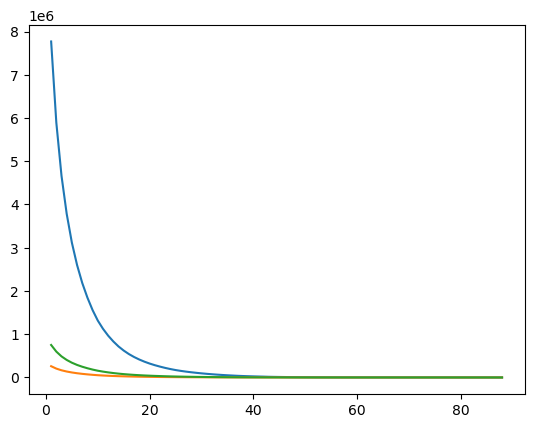

In [9]:
min_pings = 10
plt.plot(count_dict[min_pings].keys(), [count_dict[min_pings][i+1]["LA"] for i in thresholds])
plt.plot(count_dict[min_pings].keys(), [count_dict[min_pings][i+1]["SB"] for i in thresholds])
plt.plot(count_dict[min_pings].keys(), [count_dict[min_pings][i+1]["VE"] for i in thresholds])

plt.show()

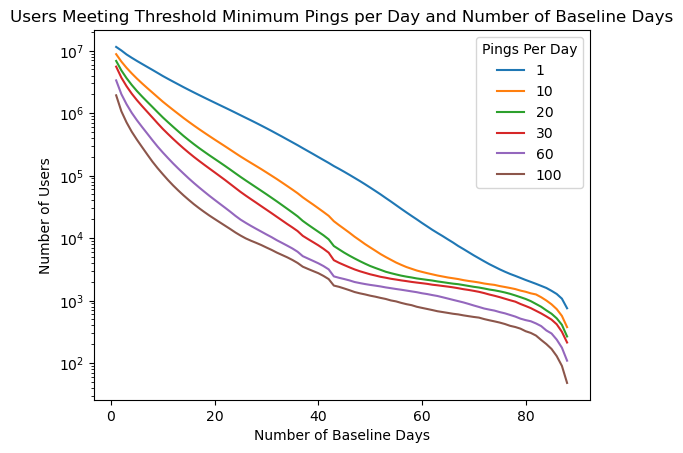

In [19]:
min_pings_list = [0,9,19,29,59,99]
for min_pings in min_pings_list:
    plt.plot(count_dict[min_pings+1].keys(),
             [count_dict[min_pings+1][i+1]["LASBVE"] for i in thresholds],
             label=min_pings+1)
plt.yscale("log")
plt.xlabel("Number of Baseline Days")
plt.ylabel("Number of Users")
plt.title("Users Meeting Threshold Minimum Pings per Day and Number of Baseline Days")
plt.legend(title="Pings Per Day")
plt.show()

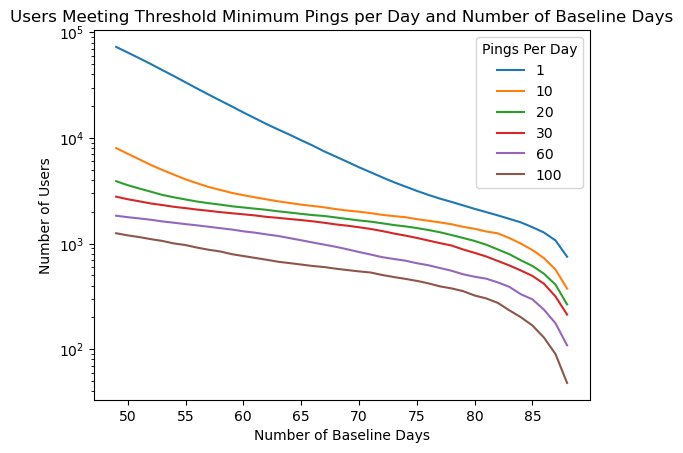

In [20]:
min_pings_list = [0,9,19,29,59,99]
for min_pings in min_pings_list:
    plt.plot(list(count_dict[min_pings+1].keys())[-40:],
             [count_dict[min_pings+1][i+1]["LASBVE"] for i in thresholds][-40:],
             label=min_pings+1)
plt.yscale("log")
plt.xlabel("Number of Baseline Days")
plt.ylabel("Number of Users")
plt.title("Users Meeting Threshold Minimum Pings per Day and Number of Baseline Days")
plt.legend(title="Pings Per Day")
plt.show()

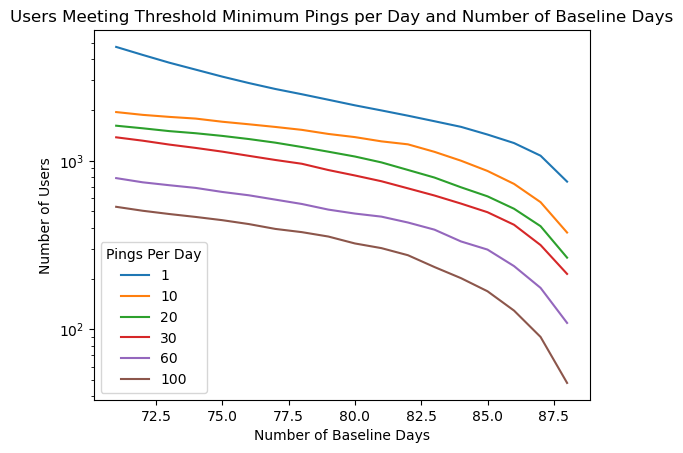

In [21]:
min_pings_list = [0,9,19,29,59,99]
for min_pings in min_pings_list:
    plt.plot(list(count_dict[min_pings+1].keys())[-18:],
             [count_dict[min_pings+1][i+1]["LASBVE"] for i in thresholds][-18:],
             label=min_pings+1)
plt.yscale("log")
plt.xlabel("Number of Baseline Days")
plt.ylabel("Number of Users")
plt.title("Users Meeting Threshold Minimum Pings per Day and Number of Baseline Days")
plt.legend(title="Pings Per Day")
plt.show()

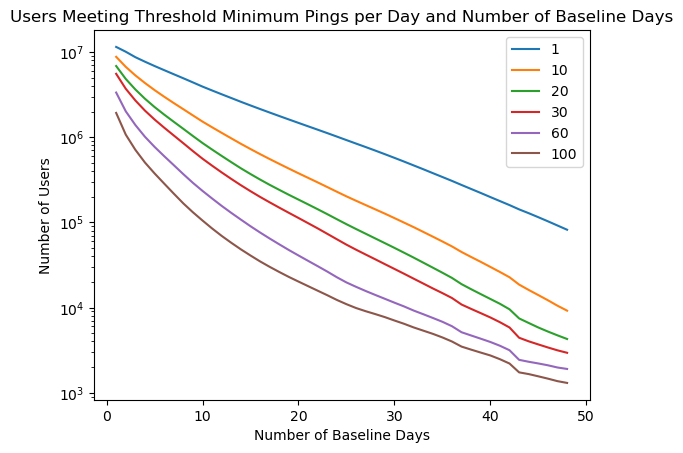

In [22]:
min_pings_list = [0,9,19,29,59,99]
for min_pings in min_pings_list:
    plt.plot(list(count_dict[min_pings+1].keys())[:48],
             [count_dict[min_pings+1][i+1]["LASBVE"] for i in thresholds][:48],
             label=min_pings+1)
plt.yscale("log")
plt.xlabel("Number of Baseline Days")
plt.ylabel("Number of Users")
plt.title("Users Meeting Threshold Minimum Pings per Day and Number of Baseline Days")
plt.legend(title="Pings Per Day")
plt.legend()
plt.show()

In [23]:
count_dict

{1: {1: {'LASBVE': 11476289, 'LA': 10224308, 'VE': 923379, 'SB': 328602},
  2: {'LASBVE': 10075245, 'LA': 8938184, 'VE': 841100, 'SB': 295961},
  3: {'LASBVE': 8697524, 'LA': 7695325, 'VE': 742958, 'SB': 259241},
  4: {'LASBVE': 7697162, 'LA': 6798131, 'SB': 231733, 'VE': 667298},
  5: {'LASBVE': 6851108, 'LA': 6041551, 'SB': 208230, 'VE': 601327},
  6: {'LASBVE': 6128659, 'LA': 5396888, 'SB': 187935, 'VE': 543836},
  7: {'LASBVE': 5487291, 'LA': 4825419, 'SB': 169916, 'VE': 491956},
  8: {'LASBVE': 4918966, 'LA': 4320236, 'SB': 153726, 'VE': 445004},
  9: {'LASBVE': 4398065, 'LA': 3858079, 'SB': 138701, 'VE': 401285},
  10: {'LASBVE': 3927348, 'LA': 3441276, 'VE': 361159, 'SB': 124913},
  11: {'LASBVE': 3535916, 'LA': 3094752, 'VE': 327928, 'SB': 113236},
  12: {'LASBVE': 3190506, 'LA': 2789070, 'VE': 298401, 'SB': 103035},
  13: {'LASBVE': 2883042, 'LA': 2517322, 'VE': 271771, 'SB': 93949},
  14: {'LASBVE': 2603948, 'LA': 2271148, 'VE': 247141, 'SB': 85659},
  15: {'LASBVE': 2359940,

In [52]:
flattened_data = {
    (l1, l2, key): value
    for l1, inner_dict in count_dict.items()
    for l2, innermost_dict in inner_dict.items()
    for key, value in innermost_dict.items()
}

# Create a MultiIndex from the flattened dictionary's keys
multi_index = pd.MultiIndex.from_tuples(flattened_data.keys(), names=['Pings Per Day', '# Baseline Days', 'County'])

# Create the DataFrame using the MultiIndex and values
df_table = pd.DataFrame(list(flattened_data.values()), index=multi_index, columns=['Data'])
df_table = df_table.unstack(level=1)
df_table

Data                                                \
# Baseline Days             1         2        3        4        5        6    
Pings Per Day County                                                           
1             LA      10224308   8938184  7695325  6798131  6041551  5396888   
              LASBVE  11476289  10075245  8697524  7697162  6851108  6128659   
              SB        328602    295961   259241   231733   208230   187935   
              VE        923379    841100   742958   667298   601327   543836   
10            LA       7769469   5892948  4662674  3784545  3117250  2601189   
              LASBVE   8781645   6696185  5316505  4328026  3574383  2989634   
              SB        260518    205067   166152   137780   115728    98127   
              VE        751658    598170   487679   405701   341405   290318   
20            LA       6039886   4237804  3175265  2463131  1963229  1596839   
              LASBVE   6845332   4830518  3633906  2828606  2261179  1844086   
              SB        205456    149839   115328    91545    74332    61460   
              VE        599990    442875   343313   273930   223618   185787   
30            LA       4888423   3243822  2353977  1782932  1398104  1119590   
              LASBVE   5547380   3703548  2699370  2051720  1613837  1295624   
              SB        167213    115469    86068    66732    53398    43581   
              VE        491744    344257   259325   202056   162335   132453   
60            LA       2940869   1760359  1210108   877367   666072   517246   
              LASBVE   3342973   2014151  1390492  1012039   770465   599657   
              SB        100898     62897    44400    33127    25567    20206   
              VE        301206    190895   135984   101545    78826    62205   
100           LA       1694109    936150   618195   436964   324936   246434   
              LASBVE   1927593   1071935   711065   504391   376118   285802   
              SB         58247     33405    22719    16530    12576     9674   
              VE        175237    102380    70151    50897    38606    29694   

                                                          ...              \
# Baseline Days            7        8        9        10  ...    79    80   
Pings Per Day County                                      ...               
1             LA      4825419  4320236  3858079  3441276  ...  1994  1854   
              LASBVE  5487291  4918966  4398065  3927348  ...  2303  2134   
              SB       169916   153726   138701   124913  ...    82    73   
              VE       491956   445004   401285   361159  ...   227   207   
10            LA      2185890  1846277  1557504  1316023  ...  1265  1213   
              LASBVE  2518333  2131527  1801684  1525018  ...  1443  1382   
              SB        83788    71836    61473    52526  ...    42    40   
              VE       248655   213414   182707   156469  ...   136   129   
20            LA      1311458  1080787   888810   734013  ...   995   937   
              LASBVE  1518046  1253765  1032863   854332  ...  1132  1060   
              SB        51255    43052    35865    29944  ...    32    32   
              VE       155333   129926   108188    90375  ...   105    91   
30            LA       904191   731216   589836   479294  ...   774   717   
              LASBVE  1048747   849807   686841   559276  ...   881   818   
              SB        35798    29401    24073    19879  ...    27    26   
              VE       108758    89190    72932    60103  ...    80    75   
60            LA       404805   316131   249561   200664  ...   461   438   
              LASBVE   470375   368324   291155   234310  ...   513   486   
              SB        16103    12951    10363     8401  ...    13    12   
              VE        49467    39242    31231    25245  ...    39    36   
100           LA       187518   143503   112896    90414  ...   319   293   
              LAS

In [57]:
# pd.options.display.float_format = '${:,.2f}'.format
display(df_table.loc[(slice(None), "LASBVE"), ::10].map('{:,}'.format))

Data                                          \
# Baseline Days               1          11         21       31       41   
Pings Per Day County                                                       
1             LASBVE  11,476,289  3,535,916  1,343,282  517,879  177,910   
10            LASBVE   8,781,645  1,307,451    333,661   99,517   26,167   
20            LASBVE   6,845,332    715,969    162,833   44,096   11,079   
30            LASBVE   5,547,380    463,293     97,969   24,980    6,735   
60            LASBVE   3,342,973    190,764     35,392   10,324    3,564   
100           LASBVE   1,927,593     84,860     17,862    6,458    2,478   

                                                    
# Baseline Days           51      61     71     81  
Pings Per Day County                                
1             LASBVE  56,896  15,391  4,741  1,990  
10            LASBVE   6,283   2,744  1,946  1,304  
20            LASBVE   3,324   2,143  1,615    978  
30            LASBVE   2,516   1,850  1,378    756  
60            LASBVE   1,732   1,270    789    466  
100           LASBVE   1,153     733    533    303

In [49]:
df_table.loc[(slice(None), "LASBVE"), :]

Data                                             
Pings Per Day                1        10       20       30       60       100
# Baseline Days County                                                       
1               LASBVE  11476289  8781645  6845332  5547380  3342973  1927593
2               LASBVE  10075245  6696185  4830518  3703548  2014151  1071935
3               LASBVE   8697524  5316505  3633906  2699370  1390492   711065
4               LASBVE   7697162  4328026  2828606  2051720  1012039   504391
5               LASBVE   6851108  3574383  2261179  1613837   770465   376118
...                          ...      ...      ...      ...      ...      ...
84              LASBVE      1590     1001      696      557      332      201
85              LASBVE      1431      870      615      495      297      168
86              LASBVE      1274      729      519      417      237      129
87              LASBVE      1072      568      409      316      176       90
88              LASBVE       752      375      266      213      109       48

[88 rows x 6 columns]

In [48]:
df_table.loc[(slice(None), "LASBVE"), :].iloc(axis=1)[::8]

,,Data
,Pings Per Day,1
# Baseline Days,County,
1,LASBVE,11476289
2,LASBVE,10075245
3,LASBVE,8697524
4,LASBVE,7697162
5,LASBVE,6851108
...,...,...
84,LASBVE,1590
85,LASBVE,1431


In [59]:
for county in list(set(df_table.index.get_level_values(1))):
    display(df_table.loc[(slice(None), county), ::10].map('{:,}'.format))

Data                                          \
# Baseline Days               1          11         21       31       41   
Pings Per Day County                                                       
1             LA      10,224,308  3,094,752  1,162,653  445,017  152,420   
10            LA       7,769,469  1,126,319    284,413   84,650   22,429   
20            LA       6,039,886    613,917    138,704   37,761    9,601   
30            LA       4,888,423    396,355     83,698   21,533    5,934   
60            LA       2,940,869    163,373     30,673    9,100    3,190   
100           LA       1,694,109     72,978     15,659    5,769    2,228   

                                                    
# Baseline Days           51      61     71     81  
Pings Per Day County                                
1             LA      48,576  13,196  4,082  1,729  
10            LA       5,430   2,418  1,712  1,150  
20            LA       2,930   1,902  1,422    861  
30            LA       2,237   1,643  1,217    667  
60            LA       1,549   1,132    703    420  
100           LA       1,030     665    480    274

Data                                              \
# Baseline Days            1        11      21      31     41     51   61   
Pings Per Day County                                                        
1             SB      328,602  113,236  47,172  19,560  7,289  2,676  797   
10            SB      260,518   45,532  12,691   3,985  1,125    283   78   
20            SB      205,456   25,513   6,169   1,745    443    100   58   
30            SB      167,213   16,631   3,747     981    243     66   47   
60            SB      100,898    6,847   1,274     345     96     42   32   
100           SB       58,247    3,022     577     180     57     25   17   

                               
# Baseline Days        71  81  
Pings Per Day County           
1             SB      228  68  
10            SB       57  37  
20            SB       44  31  
30            SB       39  23  
60            SB       22  11  
100           SB       14   6

Data                                                  \
# Baseline Days            1        11       21      31      41     51     61   
Pings Per Day County                                                            
1             VE      923,379  327,928  133,457  53,302  18,201  5,644  1,398   
10            VE      751,658  135,600   36,557  10,882   2,613    570    248   
20            VE      599,990   76,539   17,960   4,590   1,035    294    183   
30            VE      491,744   50,307   10,524   2,466     558    213    160   
60            VE      301,206   20,544    3,445     879     278    141    106   
100           VE      175,237    8,860    1,626     509     193     98     51   

                                
# Baseline Days        71   81  
Pings Per Day County            
1             VE      431  193  
10            VE      177  117  
20            VE      149   86  
30            VE      122   66  
60            VE       64   35  
100           VE       39   23

Data                                          \
# Baseline Days               1          11         21       31       41   
Pings Per Day County                                                       
1             LASBVE  11,476,289  3,535,916  1,343,282  517,879  177,910   
10            LASBVE   8,781,645  1,307,451    333,661   99,517   26,167   
20            LASBVE   6,845,332    715,969    162,833   44,096   11,079   
30            LASBVE   5,547,380    463,293     97,969   24,980    6,735   
60            LASBVE   3,342,973    190,764     35,392   10,324    3,564   
100           LASBVE   1,927,593     84,860     17,862    6,458    2,478   

                                                    
# Baseline Days           51      61     71     81  
Pings Per Day County                                
1             LASBVE  56,896  15,391  4,741  1,990  
10            LASBVE   6,283   2,744  1,946  1,304  
20            LASBVE   3,324   2,143  1,615    978  
30            LASBVE   2,516   1,850  1,378    756  
60            LASBVE   1,732   1,270    789    466  
100           LASBVE   1,153     733    533    303